Part a

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import pairwise_distances
from scipy.spatial.distance import mahalanobis
from sklearn.metrics import classification_report

# Loading the data
red_wine_data = pd.read_csv('winequality-red.csv', sep=';')
white_wine_data = pd.read_csv('winequality-white.csv', sep=';')

# Displaying first five rows of each dataset(head)
print("Red Wine Data:")
print(red_wine_data.head())
print("\nWhite Wine Data:")
print(white_wine_data.head())

Red Wine Data:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2    

Part b

In [4]:
# Combining both datasets for the purposes of classification
red_wine_data['wine_type'] = 'red'
white_wine_data['wine_type'] = 'white'
wine_data = pd.concat([red_wine_data, white_wine_data], ignore_index=True)

# Splitting the data into features and labels
X = wine_data.drop(columns=['quality', 'wine_type'])
y = wine_data['wine_type']

# Spliting into training, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.33, random_state=42)

print("Training set size:", X_train.shape)
print("Validation set size:", X_val.shape)
print("Test set size:", X_test.shape)

Training set size: (4547, 11)
Validation set size: (1306, 11)
Test set size: (644, 11)


Part c

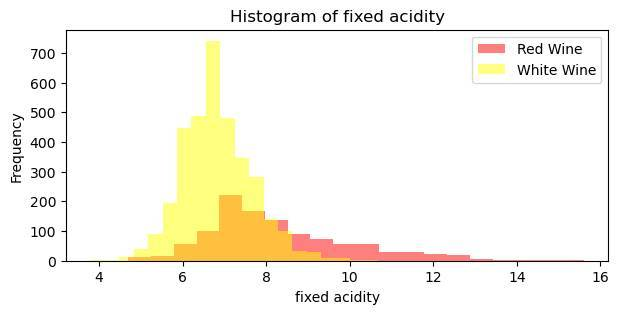

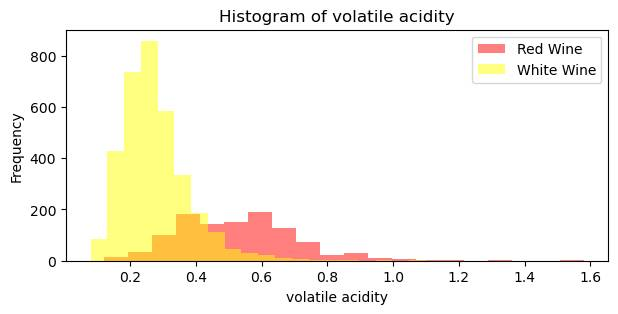

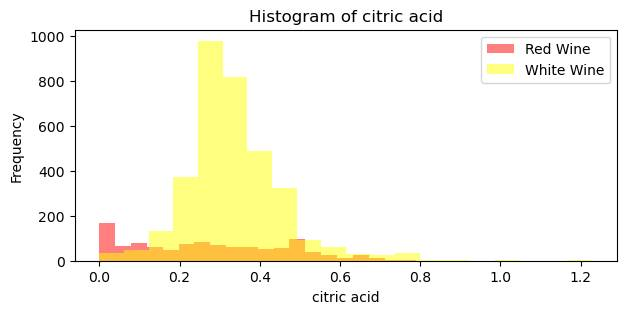

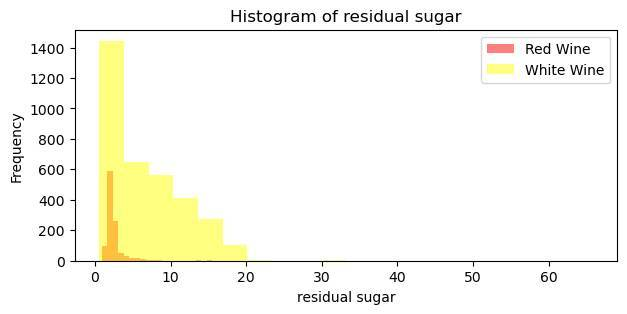

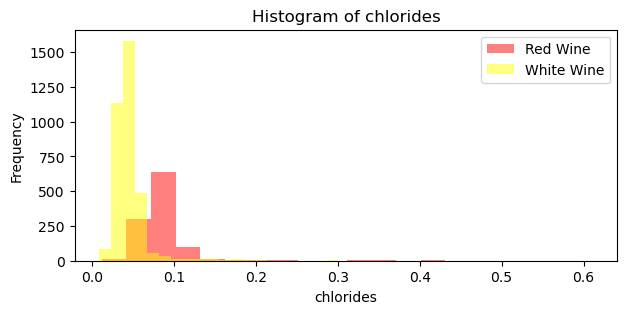

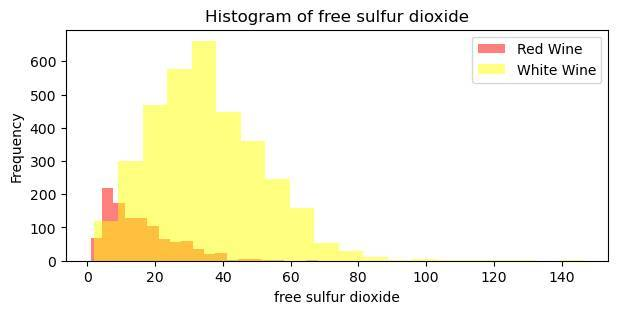

[Some figures were removed to keep the repository small; see report.pdf]


In [9]:
# Plotting histograms for each feature by class
features = X.columns
for feature in features:
    plt.figure(figsize=(7, 3))
    plt.hist(X_train[y_train == 'red'][feature], bins=20, alpha=0.5, label='Red Wine', color='red')
    plt.hist(X_train[y_train == 'white'][feature], bins=20, alpha=0.5, label='White Wine', color='yellow')
    plt.title(f'Histogram of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

Part d

In [6]:
# Calculating centroids as prototypes for each class
red_prototype = X_train[y_train == 'red'].mean()
white_prototype = X_train[y_train == 'white'].mean()
print("Red wine prototype (centroid):")
print(red_prototype)
print("\nWhite wine prototype (centroid):")
print(white_prototype)

Red wine prototype (centroid):
fixed acidity            8.316864
volatile acidity         0.523938
citric acid              0.271568
residual sugar           2.528715
chlorides                0.086819
free sulfur dioxide     15.733364
total sulfur dioxide    45.646764
density                  0.996737
pH                       3.309836
sulphates                0.659015
alcohol                 10.414388
dtype: float64

White wine prototype (centroid):
fixed acidity             6.844145
volatile acidity          0.277736
citric acid               0.335319
residual sugar            6.388348
chlorides                 0.045621
free sulfur dioxide      35.202609
total sulfur dioxide    137.879565
density                   0.994018
pH                        3.187620
sulphates                 0.488197
alcohol                  10.511220
dtype: float64


Part e

In [7]:
cov_matrix = np.cov(X_train, rowvar=False)
cov_inv = np.linalg.inv(cov_matrix)

def mahalanobis_distance(x, prototype):
    return mahalanobis(x, prototype, cov_inv)

# Calculating distance metrics between prototypes and validation samples
distance_metrics = ['euclidean', 'cosine']

for metric in distance_metrics:
    distances = pairwise_distances(X_val, [red_prototype, white_prototype], metric=metric)
    y_pred = ['red' if d[0] < d[1] else 'white' for d in distances]
    print(f"\nValidation Results using {metric.capitalize()} Distance:")
    print(classification_report(y_val, y_pred))

# Calculating Mahalanobis distance
mahalanobis_distances = [
    [mahalanobis_distance(x, red_prototype), mahalanobis_distance(x, white_prototype)]
    for x in X_val.values
]
y_pred_mahalanobis = ['red' if d[0] < d[1] else 'white' for d in mahalanobis_distances]
print("\nValidation Results using Mahalanobis Distance:")
print(classification_report(y_val, y_pred_mahalanobis))


Validation Results using Euclidean Distance:
              precision    recall  f1-score   support

         red       0.69      0.89      0.78       339
       white       0.96      0.86      0.91       967

    accuracy                           0.87      1306
   macro avg       0.83      0.88      0.84      1306
weighted avg       0.89      0.87      0.87      1306


Validation Results using Cosine Distance:
              precision    recall  f1-score   support

         red       0.88      0.79      0.83       339
       white       0.93      0.96      0.95       967

    accuracy                           0.92      1306
   macro avg       0.90      0.88      0.89      1306
weighted avg       0.92      0.92      0.92      1306


Validation Results using Mahalanobis Distance:
              precision    recall  f1-score   support

         red       0.98      0.98      0.98       339
       white       0.99      0.99      0.99       967

    accuracy                           0.99  

Part f

In [10]:
mahalanobis_test_distances = [
    [mahalanobis_distance(x, red_prototype), mahalanobis_distance(x, white_prototype)]
    for x in X_test.values
]
y_pred = ['red' if d[0] < d[1] else 'white' for d in mahalanobis_test_distances]
print("\nTest Results using Mahalanobis Distance:")
print(classification_report(y_test, y_pred))


Test Results using Mahalanobis Distance:
              precision    recall  f1-score   support

         red       0.99      0.99      0.99       163
       white       1.00      1.00      1.00       481

    accuracy                           1.00       644
   macro avg       1.00      1.00      1.00       644
weighted avg       1.00      1.00      1.00       644

